# CS667 Project #1: Exploratory Data Analysis
## Retail Sales Dataset Analysis

**Course:** CS667 - Practical Data Science  
**Semester:** Spring 2026    

---



## Table of Contents

1. [Data Loading and Initial Inspection](#section1)
2. [Data Quality Assessment](#section2)
3. [Descriptive Statistics](#section3)
4. [Univariate Analysis](#section4)
5. [Temporal Analysis](#section5)
6. [Product Analysis](#section6)
7. [Multivariate Analysis](#section7)
8. [Outlier Detection](#section8)
9. [Business Insights & Recommendations](#section9)

## 1. Data Loading and Initial Inspection <a id='section1'></a>

In [57]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from datetime import datetime, timedelta
from scipy import stats
from scipy.stats import chi2_contingency, pearsonr, spearmanr
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor

# Configure display settings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Set visualization style
plt.style.use('seaborn-v0_8-darkgrid')


# Set random seed for reproducibility
np.random.seed(4)

print("Libraries imported successfully!")


Libraries imported successfully!


In [58]:
# Load the dataset
df = pd.read_excel('retail_sales (1).xlsx')

print("Dataset loaded successfully!")
print(f"\nDataset Dimensions: {df.shape[0]} rows × {df.shape[1]} columns")
print("\n" + "="*80)
print("FIRST 10 RECORDS:")
print("="*80)
df.head(10)

Dataset loaded successfully!

Dataset Dimensions: 1000 rows × 9 columns

FIRST 10 RECORDS:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100
5,6,2023-04-25,CUST006,Female,45,Beauty,1,30,30
6,7,2023-03-13,CUST007,Male,46,Clothing,2,25,50
7,8,2023-02-22,CUST008,Male,30,Electronics,4,25,100
8,9,2023-12-13,CUST009,Male,63,Electronics,2,300,600
9,10,2023-10-07,CUST010,Female,52,Clothing,4,50,200


In [59]:
# Display dataset information
print("DATASET INFORMATION:")
print("="*80)
df.info()
print("\n" + "="*80)
print("COLUMN DATA TYPES:")
print("="*80)
for col in df.columns:
    print(f"{col:20s} : {str(df[col].dtype):15s} | Unique: {df[col].nunique():5d}")

DATASET INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    1000 non-null   int64         
 1   Date              1000 non-null   datetime64[ns]
 2   Customer ID       1000 non-null   object        
 3   Gender            1000 non-null   object        
 4   Age               1000 non-null   int64         
 5   Product Category  1000 non-null   object        
 6   Quantity          1000 non-null   int64         
 7   Price per Unit    1000 non-null   int64         
 8   Total Amount      1000 non-null   int64         
dtypes: datetime64[ns](1), int64(5), object(3)
memory usage: 70.4+ KB

COLUMN DATA TYPES:
Transaction ID       : int64           | Unique:  1000
Date                 : datetime64[ns]  | Unique:   345
Customer ID          : object          | Unique:  1000
Gender               : ob

## 2. Data Quality Assessment <a id='section2'></a>

In [60]:
# Check for missing values
print("MISSING VALUE ANALYSIS:")
print("="*80)
missing_summary = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Percentage': (df.isnull().sum() / len(df) * 100).round(2),
    'Data_Type': df.dtypes
})
print(missing_summary)
print(f"\nTotal Missing Values: {df.isnull().sum().sum()}")


MISSING VALUE ANALYSIS:
                  Missing_Count  Percentage       Data_Type
Transaction ID                0        0.00           int64
Date                          0        0.00  datetime64[ns]
Customer ID                   0        0.00          object
Gender                        0        0.00          object
Age                           0        0.00           int64
Product Category              0        0.00          object
Quantity                      0        0.00           int64
Price per Unit                0        0.00           int64
Total Amount                  0        0.00           int64

Total Missing Values: 0


In [61]:
# Check for duplicates
print("\nDUPLICATE ANALYSIS:")
print("="*80)
duplicate_rows = df.duplicated().sum()
duplicate_transactions = df['Transaction ID'].duplicated().sum()

print(f"Duplicate Rows: {duplicate_rows}")
print(f"Duplicate Transaction IDs: {duplicate_transactions}")

if duplicate_rows == 0 and duplicate_transactions == 0:
    print("\n No duplicates found - data integrity maintained!")
else:
    print("\n Duplicates detected - investigation required")


DUPLICATE ANALYSIS:
Duplicate Rows: 0
Duplicate Transaction IDs: 0

 No duplicates found - data integrity maintained!


In [62]:
# Data validation checks
print("\nDATA VALIDATION CHECKS:")
print("="*80)

# Check if Total Amount = Quantity * Price per Unit
df['Calculated_Total'] = df['Quantity'] * df['Price per Unit']
discrepancies = (df['Total Amount'] != df['Calculated_Total']).sum()
print(f"1. Total Amount Calculation Check: {discrepancies} discrepancies found")

# Check for negative values
negative_checks = {
    'Quantity': (df['Quantity'] < 0).sum(),
    'Price per Unit': (df['Price per Unit'] < 0).sum(),
    'Total Amount': (df['Total Amount'] < 0).sum()
}
print(f"\n2. Negative Value Check:")
for col, count in negative_checks.items():
    print(f"   {col}: {count} negative values")

# Check age range
print(f"\n3. Age Range Check:")
print(f"   Minimum Age: {df['Age'].min()}")
print(f"   Maximum Age: {df['Age'].max()}")
print(f"   Ages outside 18-100 range: {((df['Age'] < 18) | (df['Age'] > 100)).sum()}")

# Check date range
print(f"\n4. Date Range Check:")
print(f"   Earliest Transaction: {df['Date'].min().date()}")
print(f"   Latest Transaction: {df['Date'].max().date()}")
print(f"   Date Range: {(df['Date'].max() - df['Date'].min()).days} days")

df.drop('Calculated_Total', axis=1, inplace=True)


DATA VALIDATION CHECKS:
1. Total Amount Calculation Check: 0 discrepancies found

2. Negative Value Check:
   Quantity: 0 negative values
   Price per Unit: 0 negative values
   Total Amount: 0 negative values

3. Age Range Check:
   Minimum Age: 18
   Maximum Age: 64
   Ages outside 18-100 range: 0

4. Date Range Check:
   Earliest Transaction: 2023-01-01
   Latest Transaction: 2024-01-01
   Date Range: 365 days


## 3. Descriptive Statistics <a id='section3'></a>

In [63]:
# Comprehensive descriptive statistics for numerical features
print("DESCRIPTIVE STATISTICS - NUMERICAL FEATURES:")
print("="*80)
print(df.describe().T)

DESCRIPTIVE STATISTICS - NUMERICAL FEATURES:
                 count                           mean                  min  \
Transaction ID 1000.00                         500.50                 1.00   
Date              1000  2023-07-03 00:25:55.200000256  2023-01-01 00:00:00   
Age            1000.00                          41.39                18.00   
Quantity       1000.00                           2.51                 1.00   
Price per Unit 1000.00                         179.89                25.00   
Total Amount   1000.00                         456.00                25.00   

                                25%                  50%                  75%  \
Transaction ID               250.75               500.50               750.25   
Date            2023-04-08 00:00:00  2023-06-29 12:00:00  2023-10-04 00:00:00   
Age                           29.00                42.00                53.00   
Quantity                       1.00                 3.00                 4.00   
Pri

In [64]:
# Additional statistical measures
numerical_cols = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']

print("\nADVANCED STATISTICAL MEASURES:")
print("="*80)

stats_df = pd.DataFrame({
    'Mean': df[numerical_cols].mean(),
    'Median': df[numerical_cols].median(),
    'Mode': df[numerical_cols].mode().iloc[0],
    'Std Dev': df[numerical_cols].std(),
    'Variance': df[numerical_cols].var(),
    'Skewness': df[numerical_cols].skew(),
    'Kurtosis': df[numerical_cols].kurtosis(),
    'IQR': df[numerical_cols].quantile(0.75) - df[numerical_cols].quantile(0.25),
    'CV (%)': (df[numerical_cols].std() / df[numerical_cols].mean() * 100)
})

print(stats_df.round(2))


ADVANCED STATISTICAL MEASURES:
                 Mean  Median  Mode  Std Dev  Variance  Skewness  Kurtosis  \
Age             41.39   42.00 43.00    13.68    187.18     -0.05     -1.20   
Quantity         2.51    3.00  4.00     1.13      1.28     -0.01     -1.39   
Price per Unit 179.89   50.00 50.00   189.68  35979.02      0.74     -1.14   
Total Amount   456.00  135.00 50.00   560.00 313597.35      1.38      0.82   

                  IQR  CV (%)  
Age             24.00   33.05  
Quantity         3.00   45.06  
Price per Unit 270.00  105.44  
Total Amount   840.00  122.81  


In [65]:
# Categorical features summary
print("\nCATEGORICAL FEATURES SUMMARY:")
print("="*80)

categorical_cols = ['Gender', 'Product Category']

for col in categorical_cols:
    print(f"\n{col}:")
    print("-" * 40)
    value_counts = df[col].value_counts()
    percentage = (df[col].value_counts(normalize=True) * 100).round(2)
    summary = pd.DataFrame({
        'Count': value_counts,
        'Percentage': percentage
    })
    print(summary)
    print(f"Unique Values: {df[col].nunique()}")


CATEGORICAL FEATURES SUMMARY:

Gender:
----------------------------------------
        Count  Percentage
Gender                   
Female    510       51.00
Male      490       49.00
Unique Values: 2

Product Category:
----------------------------------------
                  Count  Percentage
Product Category                   
Clothing            351       35.10
Electronics         342       34.20
Beauty              307       30.70
Unique Values: 3


In [66]:
# Customer ID analysis
print("\nCUSTOMER ANALYSIS:")
print("="*80)
unique_customers = df['Customer ID'].nunique()
total_transactions = len(df)
avg_transactions_per_customer = total_transactions / unique_customers

print(f"Total Unique Customers: {unique_customers}")
print(f"Total Transactions: {total_transactions}")
print(f"Average Transactions per Customer: {avg_transactions_per_customer:.2f}")
print(f"\nCustomer Frequency Distribution:")
customer_frequency = df['Customer ID'].value_counts()
print(f"  Customers with 1 transaction: {(customer_frequency == 1).sum()}")
print(f"  Customers with 2+ transactions: {(customer_frequency >= 2).sum()}")
print(f"  Maximum transactions by a customer: {customer_frequency.max()}")


CUSTOMER ANALYSIS:
Total Unique Customers: 1000
Total Transactions: 1000
Average Transactions per Customer: 1.00

Customer Frequency Distribution:
  Customers with 1 transaction: 1000
  Customers with 2+ transactions: 0
  Maximum transactions by a customer: 1


## 4. Univariate Analysis <a id='section4'></a>

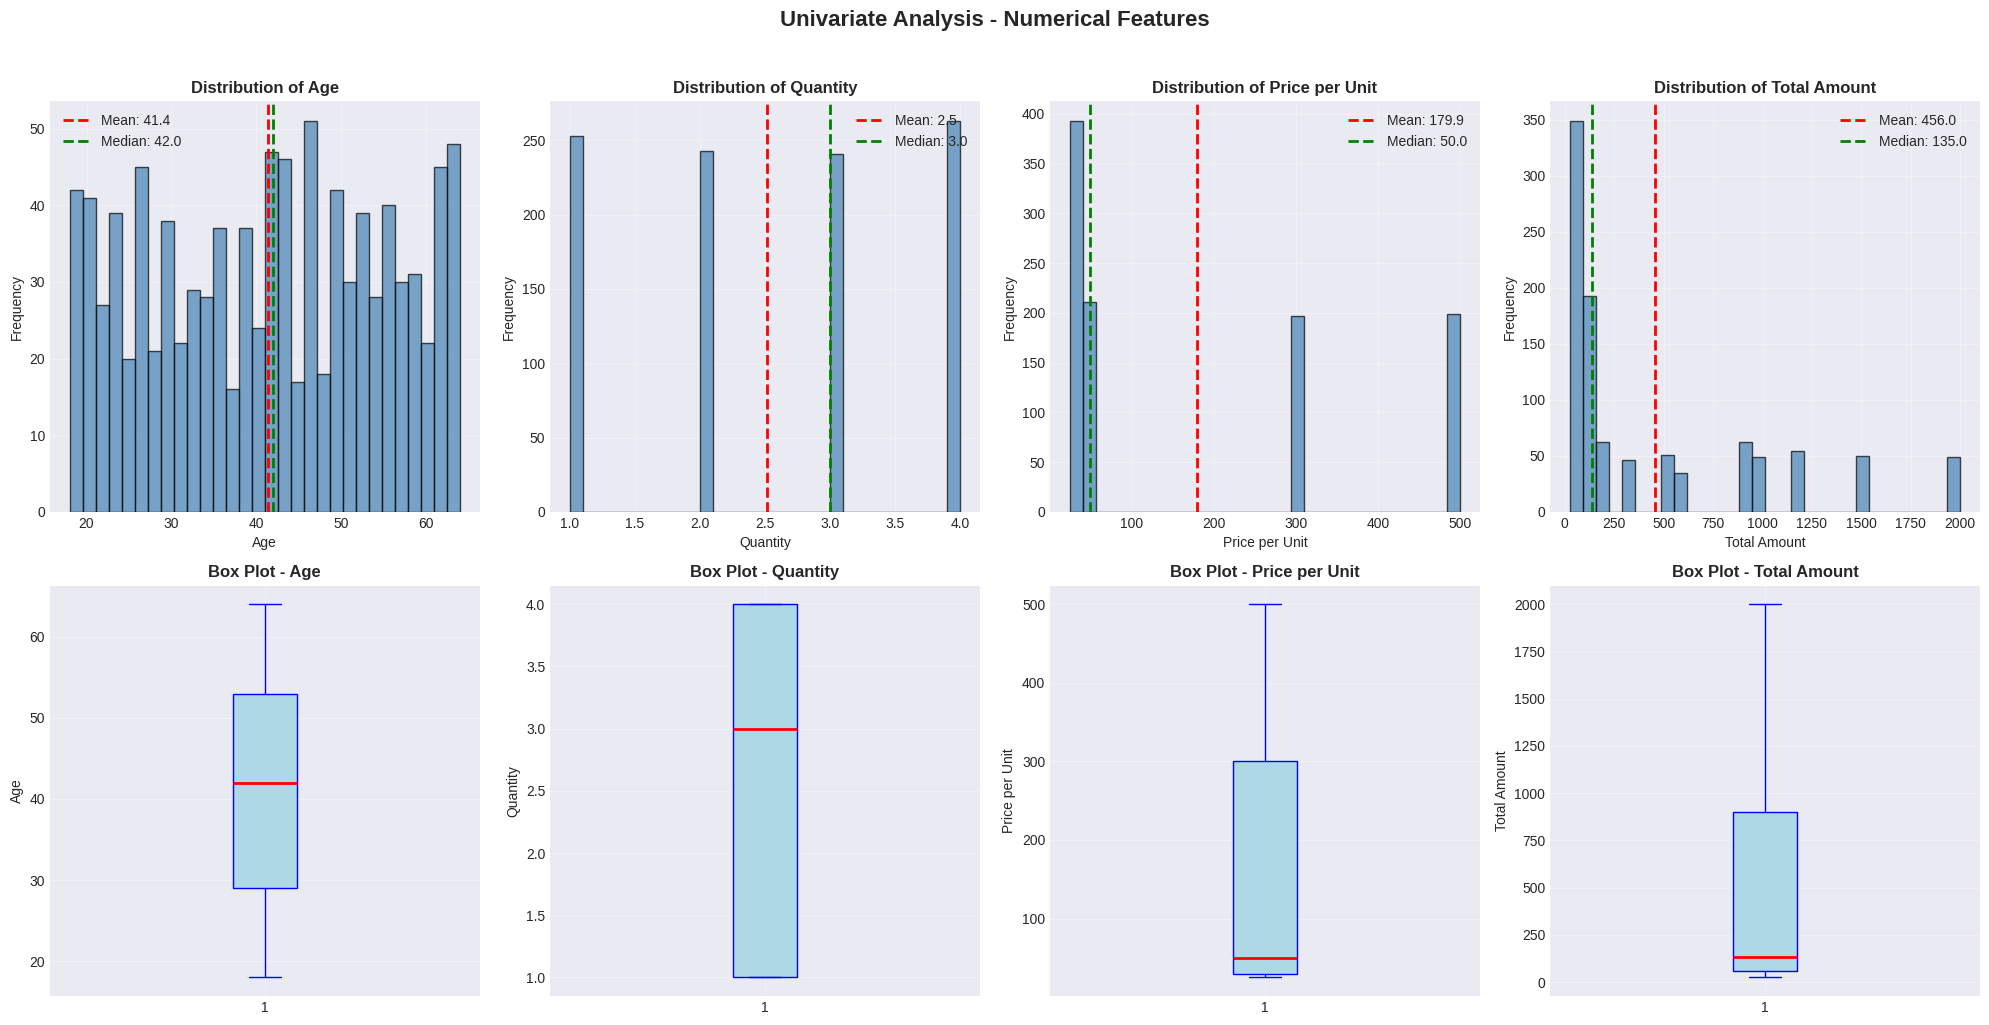

Univariate analysis visualizations generated successfully!


In [67]:
# Visualizations for numerical features
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle('Univariate Analysis - Numerical Features', fontsize=16, fontweight='bold', y=1.02)

numerical_features = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']

for idx, col in enumerate(numerical_features):
    # Histogram
    axes[0, idx].hist(df[col], bins=30, edgecolor='black', alpha=0.7, color='steelblue')
    axes[0, idx].set_title(f'Distribution of {col}', fontweight='bold')
    axes[0, idx].set_xlabel(col)
    axes[0, idx].set_ylabel('Frequency')
    axes[0, idx].grid(True, alpha=0.3)

    # Add mean and median lines
    axes[0, idx].axvline(df[col].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df[col].mean():.1f}')
    axes[0, idx].axvline(df[col].median(), color='green', linestyle='--', linewidth=2, label=f'Median: {df[col].median():.1f}')
    axes[0, idx].legend()

    # Box plot
    axes[1, idx].boxplot(df[col], vert=True, patch_artist=True,
                        boxprops=dict(facecolor='lightblue', color='blue'),
                        whiskerprops=dict(color='blue'),
                        capprops=dict(color='blue'),
                        medianprops=dict(color='red', linewidth=2))
    axes[1, idx].set_title(f'Box Plot - {col}', fontweight='bold')
    axes[1, idx].set_ylabel(col)
    axes[1, idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Univariate analysis visualizations generated successfully!")

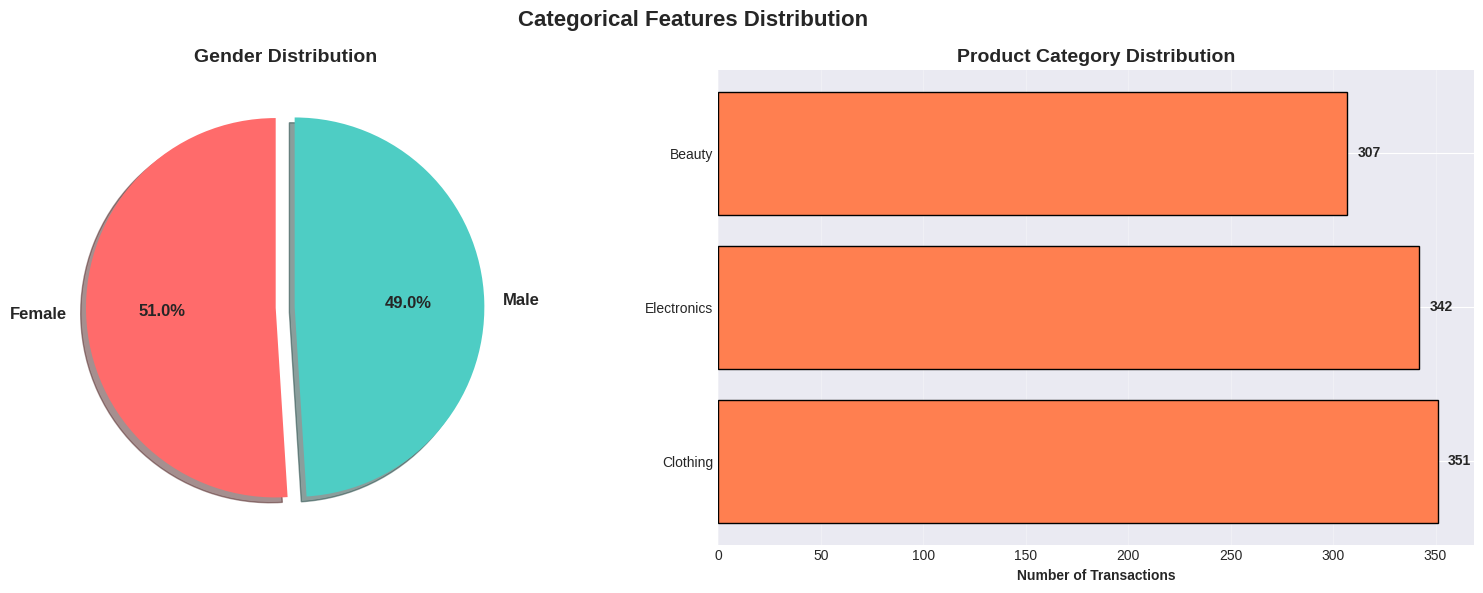

In [68]:
# Categorical features visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Categorical Features Distribution', fontsize=16, fontweight='bold')

# Gender distribution
gender_counts = df['Gender'].value_counts()
colors_gender = ['#FF6B6B', '#4ECDC4']
axes[0].pie(gender_counts.values, labels=gender_counts.index, autopct='%1.1f%%',
           startangle=90, colors=colors_gender, explode=[0.05, 0.05],
           shadow=True, textprops={'fontsize': 12, 'fontweight': 'bold'})
axes[0].set_title('Gender Distribution', fontweight='bold', fontsize=14)

# Product Category distribution
category_counts = df['Product Category'].value_counts()
axes[1].barh(category_counts.index, category_counts.values, color='coral', edgecolor='black')
axes[1].set_xlabel('Number of Transactions', fontweight='bold')
axes[1].set_title('Product Category Distribution', fontweight='bold', fontsize=14)
axes[1].grid(True, alpha=0.3, axis='x')

# Add value labels on bars
for i, v in enumerate(category_counts.values):
    axes[1].text(v + 5, i, str(v), va='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 5. Temporal Analysis <a id='section5'></a>

In [69]:
# Extract temporal features
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Month_Name'] = df['Date'].dt.strftime('%B')
df['Quarter'] = df['Date'].dt.quarter
df['Day'] = df['Date'].dt.day
df['Day_of_Week'] = df['Date'].dt.dayofweek
df['Day_Name'] = df['Date'].dt.strftime('%A')
df['Week_of_Year'] = df['Date'].dt.isocalendar().week
df['Is_Weekend'] = df['Day_of_Week'].isin([5, 6]).astype(int)
df['Is_Month_Start'] = df['Date'].dt.is_month_start.astype(int)
df['Is_Month_End'] = df['Date'].dt.is_month_end.astype(int)

print("Temporal features extracted successfully!")
print("\nNew temporal features:")
print(df[['Date', 'Year', 'Month', 'Month_Name', 'Quarter', 'Day_Name', 'Week_of_Year', 'Is_Weekend']].head(10))

Temporal features extracted successfully!

New temporal features:
        Date  Year  Month Month_Name  Quarter   Day_Name  Week_of_Year  \
0 2023-11-24  2023     11   November        4     Friday            47   
1 2023-02-27  2023      2   February        1     Monday             9   
2 2023-01-13  2023      1    January        1     Friday             2   
3 2023-05-21  2023      5        May        2     Sunday            20   
4 2023-05-06  2023      5        May        2   Saturday            18   
5 2023-04-25  2023      4      April        2    Tuesday            17   
6 2023-03-13  2023      3      March        1     Monday            11   
7 2023-02-22  2023      2   February        1  Wednesday             8   
8 2023-12-13  2023     12   December        4  Wednesday            50   
9 2023-10-07  2023     10    October        4   Saturday            40   

   Is_Weekend  
0           0  
1           0  
2           0  
3           1  
4           1  
5           0  
6      

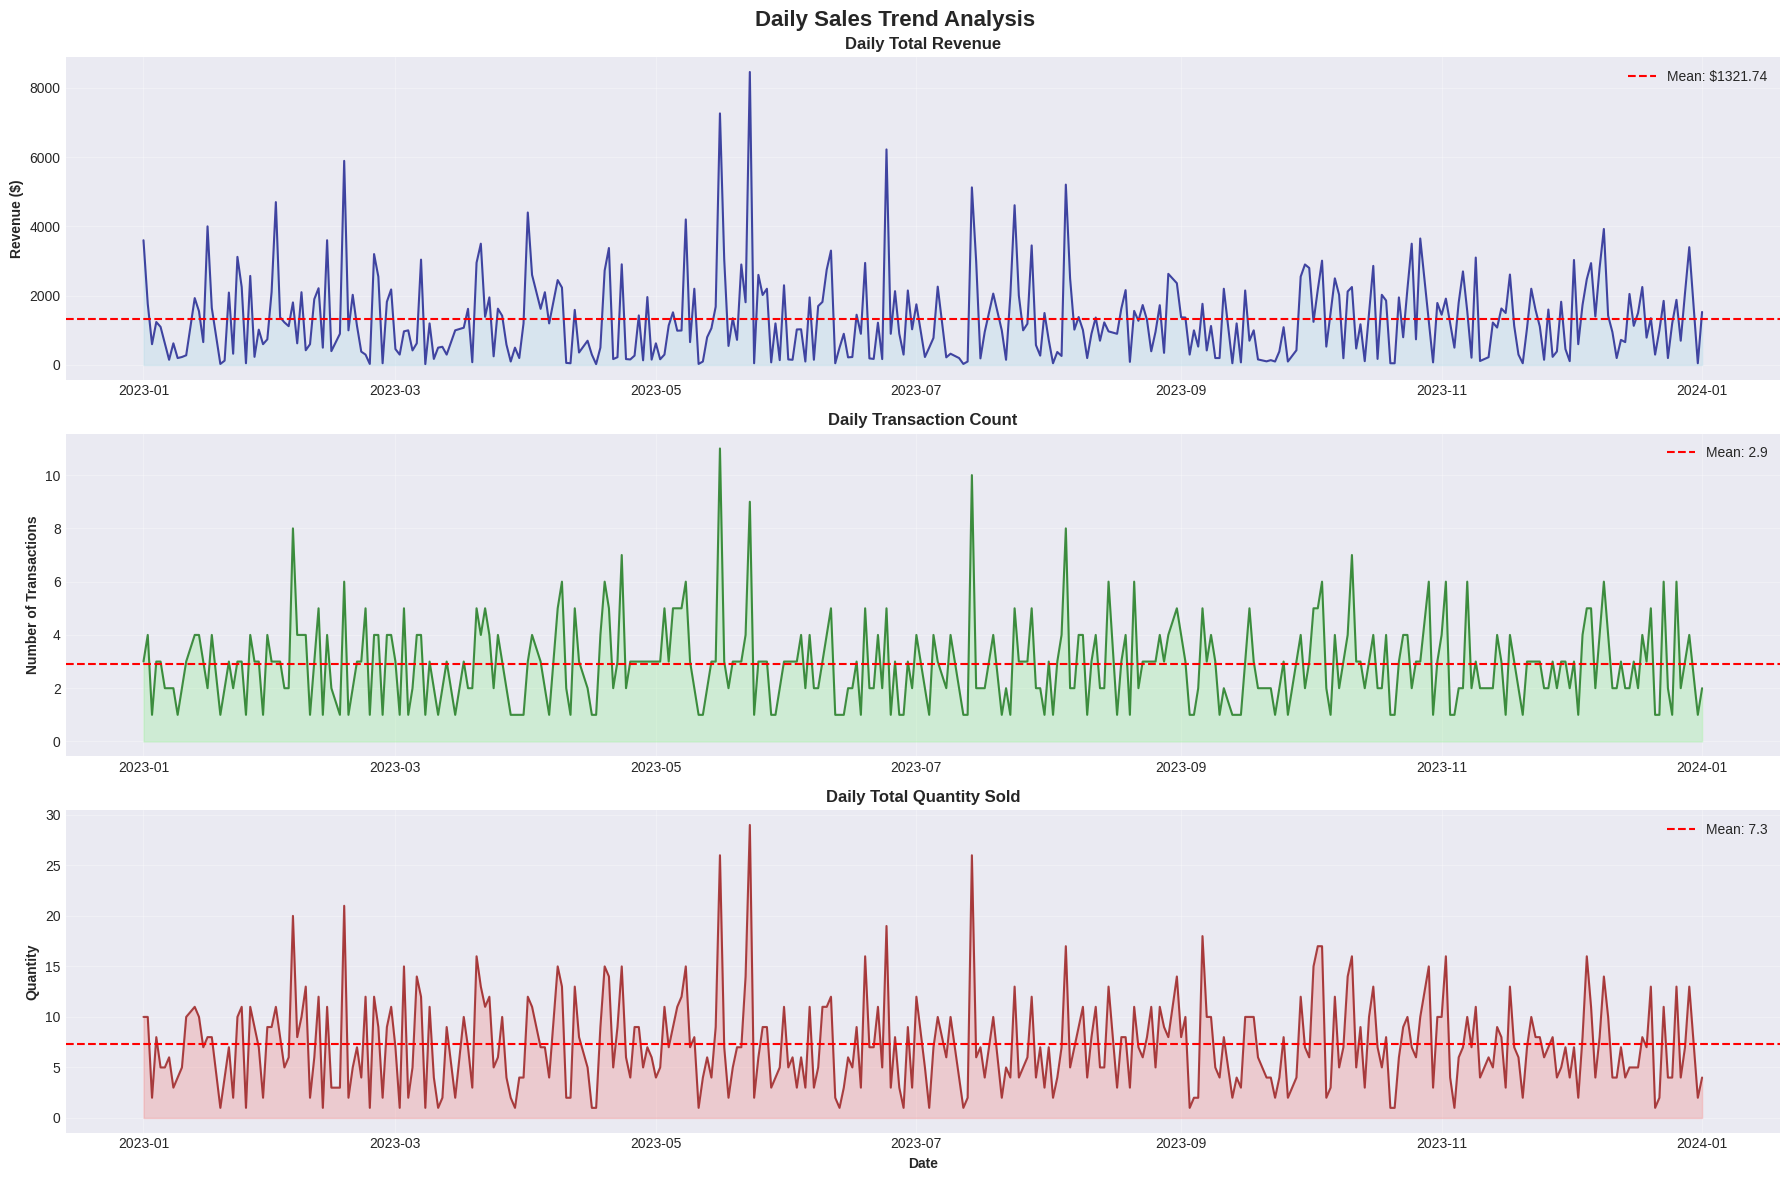


Daily Sales Summary:
Average Daily Revenue: $1321.74
Peak Daily Revenue: $8455.00 on 2023-05-23
Lowest Daily Revenue: $25.00 on 2023-03-08


In [70]:
# Time series analysis - Daily sales
daily_sales = df.groupby('Date').agg({
    'Total Amount': 'sum',
    'Transaction ID': 'count',
    'Quantity': 'sum'
}).reset_index()
daily_sales.columns = ['Date', 'Total_Revenue', 'Transaction_Count', 'Total_Quantity']

fig, axes = plt.subplots(3, 1, figsize=(18, 12))
fig.suptitle('Daily Sales Trend Analysis', fontsize=16, fontweight='bold')

# Daily revenue
axes[0].plot(daily_sales['Date'], daily_sales['Total_Revenue'], color='navy', linewidth=1.5, alpha=0.7)
axes[0].fill_between(daily_sales['Date'], daily_sales['Total_Revenue'], alpha=0.3, color='lightblue')
axes[0].set_title('Daily Total Revenue', fontweight='bold', fontsize=12)
axes[0].set_ylabel('Revenue ($)', fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].axhline(daily_sales['Total_Revenue'].mean(), color='red', linestyle='--',
               label=f"Mean: ${daily_sales['Total_Revenue'].mean():.2f}")
axes[0].legend()

# Daily transaction count
axes[1].plot(daily_sales['Date'], daily_sales['Transaction_Count'], color='darkgreen', linewidth=1.5, alpha=0.7)
axes[1].fill_between(daily_sales['Date'], daily_sales['Transaction_Count'], alpha=0.3, color='lightgreen')
axes[1].set_title('Daily Transaction Count', fontweight='bold', fontsize=12)
axes[1].set_ylabel('Number of Transactions', fontweight='bold')
axes[1].grid(True, alpha=0.3)
axes[1].axhline(daily_sales['Transaction_Count'].mean(), color='red', linestyle='--',
               label=f"Mean: {daily_sales['Transaction_Count'].mean():.1f}")
axes[1].legend()

# Daily quantity sold
axes[2].plot(daily_sales['Date'], daily_sales['Total_Quantity'], color='darkred', linewidth=1.5, alpha=0.7)
axes[2].fill_between(daily_sales['Date'], daily_sales['Total_Quantity'], alpha=0.3, color='lightcoral')
axes[2].set_title('Daily Total Quantity Sold', fontweight='bold', fontsize=12)
axes[2].set_ylabel('Quantity', fontweight='bold')
axes[2].set_xlabel('Date', fontweight='bold')
axes[2].grid(True, alpha=0.3)
axes[2].axhline(daily_sales['Total_Quantity'].mean(), color='red', linestyle='--',
               label=f"Mean: {daily_sales['Total_Quantity'].mean():.1f}")
axes[2].legend()

plt.tight_layout()
plt.show()

print(f"\nDaily Sales Summary:")
print(f"Average Daily Revenue: ${daily_sales['Total_Revenue'].mean():.2f}")
print(f"Peak Daily Revenue: ${daily_sales['Total_Revenue'].max():.2f} on {daily_sales.loc[daily_sales['Total_Revenue'].idxmax(), 'Date'].date()}")
print(f"Lowest Daily Revenue: ${daily_sales['Total_Revenue'].min():.2f} on {daily_sales.loc[daily_sales['Total_Revenue'].idxmin(), 'Date'].date()}")

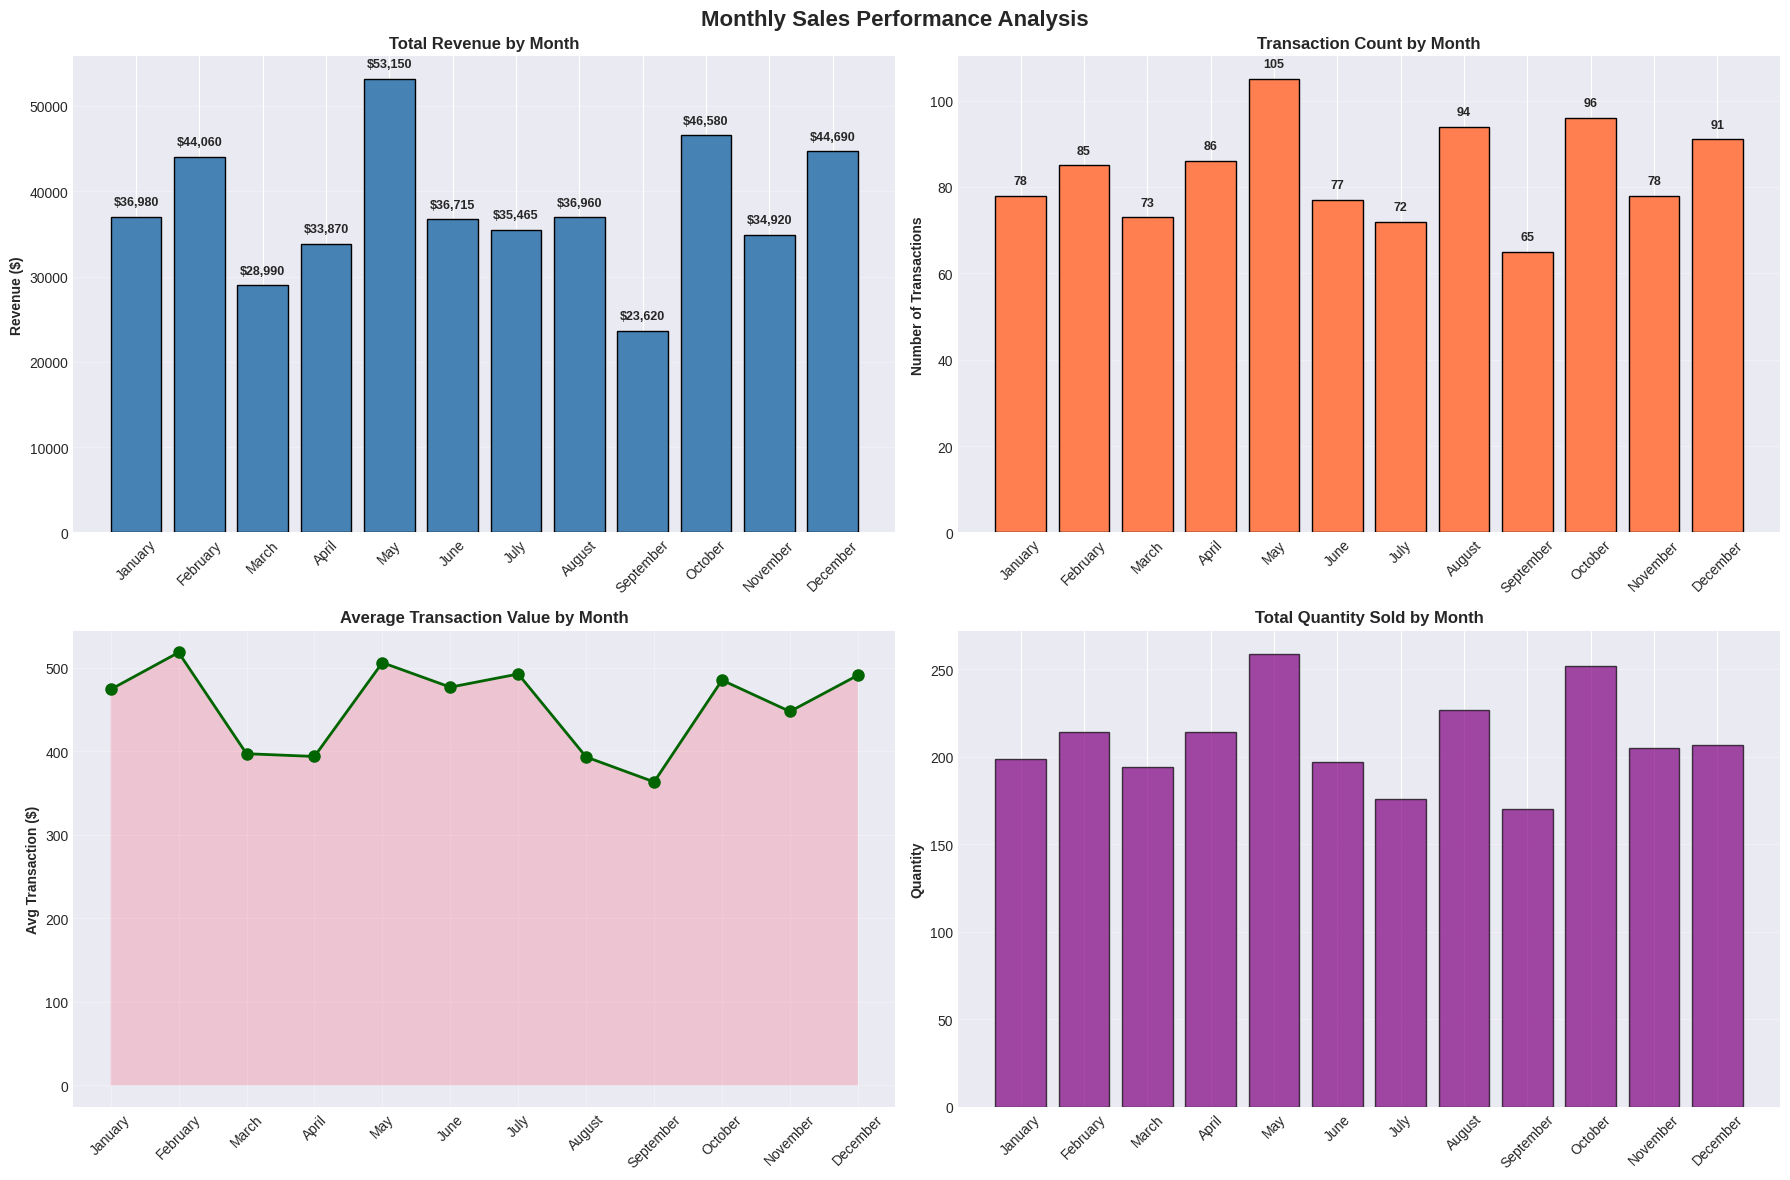


MONTHLY SALES SUMMARY:
    Month  Total_Revenue  Avg_Transaction_Value  Transaction_Count  Total_Quantity
  January          36980                 474.10                 78             199
 February          44060                 518.35                 85             214
    March          28990                 397.12                 73             194
    April          33870                 393.84                 86             214
      May          53150                 506.19                105             259
     June          36715                 476.82                 77             197
     July          35465                 492.57                 72             176
   August          36960                 393.19                 94             227
September          23620                 363.38                 65             170
  October          46580                 485.21                 96             252
 November          34920                 447.69                

In [71]:
# Monthly analysis
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

monthly_sales = df.groupby('Month_Name').agg({
    'Total Amount': ['sum', 'mean', 'count'],
    'Quantity': 'sum'
}).reset_index()
monthly_sales.columns = ['Month', 'Total_Revenue', 'Avg_Transaction_Value', 'Transaction_Count', 'Total_Quantity']
monthly_sales['Month'] = pd.Categorical(monthly_sales['Month'], categories=month_order, ordered=True)
monthly_sales = monthly_sales.sort_values('Month')

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('Monthly Sales Performance Analysis', fontsize=16, fontweight='bold')

# Monthly revenue
axes[0, 0].bar(monthly_sales['Month'], monthly_sales['Total_Revenue'], color='steelblue', edgecolor='black')
axes[0, 0].set_title('Total Revenue by Month', fontweight='bold')
axes[0, 0].set_ylabel('Revenue ($)', fontweight='bold')
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(monthly_sales['Total_Revenue']):
    axes[0, 0].text(i, v + 1000, f'${v:,.0f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

# Transaction count by month
axes[0, 1].bar(monthly_sales['Month'], monthly_sales['Transaction_Count'], color='coral', edgecolor='black')
axes[0, 1].set_title('Transaction Count by Month', fontweight='bold')
axes[0, 1].set_ylabel('Number of Transactions', fontweight='bold')
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(monthly_sales['Transaction_Count']):
    axes[0, 1].text(i, v + 2, f'{v}', ha='center', va='bottom', fontsize=9, fontweight='bold')

# Average transaction value by month
axes[1, 0].plot(monthly_sales['Month'], monthly_sales['Avg_Transaction_Value'],
               marker='o', linewidth=2, markersize=8, color='darkgreen')
axes[1, 0].set_title('Average Transaction Value by Month', fontweight='bold')
axes[1, 0].set_ylabel('Avg Transaction ($)', fontweight='bold')
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].fill_between(range(len(monthly_sales)), monthly_sales['Avg_Transaction_Value'], alpha=0.3)

# Total quantity by month
axes[1, 1].bar(monthly_sales['Month'], monthly_sales['Total_Quantity'], color='purple', edgecolor='black', alpha=0.7)
axes[1, 1].set_title('Total Quantity Sold by Month', fontweight='bold')
axes[1, 1].set_ylabel('Quantity', fontweight='bold')
axes[1, 1].tick_params(axis='x', rotation=45)
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("\nMONTHLY SALES SUMMARY:")
print("="*80)
print(monthly_sales.to_string(index=False))

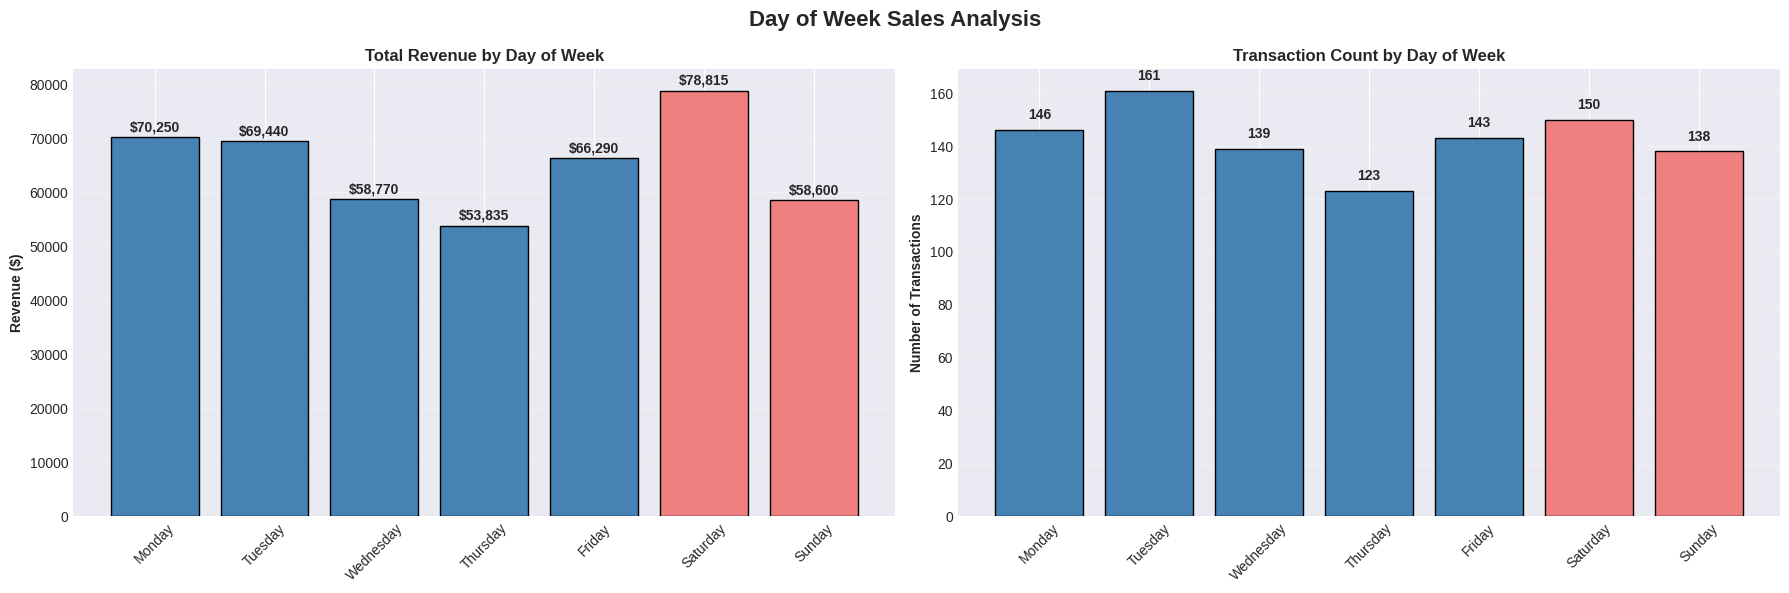


DAY OF WEEK ANALYSIS:
      Day  Total_Revenue  Avg_Transaction_Value  Transaction_Count
   Monday          70250                 481.16                146
  Tuesday          69440                 431.30                161
Wednesday          58770                 422.81                139
 Thursday          53835                 437.68                123
   Friday          66290                 463.57                143
 Saturday          78815                 525.43                150
   Sunday          58600                 424.64                138

WEEKEND vs WEEKDAY COMPARISON:
Weekend Revenue: $137,415.00 (288 transactions)
Weekday Revenue: $318,585.00 (712 transactions)
Weekend Avg Transaction: $477.14
Weekday Avg Transaction: $447.45


In [72]:
# Day of week analysis
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

dow_sales = df.groupby('Day_Name').agg({
    'Total Amount': ['sum', 'mean'],
    'Transaction ID': 'count'
}).reset_index()
dow_sales.columns = ['Day', 'Total_Revenue', 'Avg_Transaction_Value', 'Transaction_Count']
dow_sales['Day'] = pd.Categorical(dow_sales['Day'], categories=day_order, ordered=True)
dow_sales = dow_sales.sort_values('Day')

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Day of Week Sales Analysis', fontsize=16, fontweight='bold')

# Revenue by day of week
colors = ['lightcoral' if day in ['Saturday', 'Sunday'] else 'steelblue' for day in dow_sales['Day']]
axes[0].bar(dow_sales['Day'], dow_sales['Total_Revenue'], color=colors, edgecolor='black')
axes[0].set_title('Total Revenue by Day of Week', fontweight='bold')
axes[0].set_ylabel('Revenue ($)', fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(dow_sales['Total_Revenue']):
    axes[0].text(i, v + 500, f'${v:,.0f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

# Transaction count by day of week
axes[1].bar(dow_sales['Day'], dow_sales['Transaction_Count'], color=colors, edgecolor='black')
axes[1].set_title('Transaction Count by Day of Week', fontweight='bold')
axes[1].set_ylabel('Number of Transactions', fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(dow_sales['Transaction_Count']):
    axes[1].text(i, v + 3, f'{v}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

print("\nDAY OF WEEK ANALYSIS:")
print("="*80)
print(dow_sales.to_string(index=False))

# Weekend vs Weekday comparison
weekend_sales = df[df['Is_Weekend'] == 1]['Total Amount'].sum()
weekday_sales = df[df['Is_Weekend'] == 0]['Total Amount'].sum()
weekend_trans = df[df['Is_Weekend'] == 1].shape[0]
weekday_trans = df[df['Is_Weekend'] == 0].shape[0]

print("\n" + "="*80)
print("WEEKEND vs WEEKDAY COMPARISON:")
print("="*80)
print(f"Weekend Revenue: ${weekend_sales:,.2f} ({weekend_trans} transactions)")
print(f"Weekday Revenue: ${weekday_sales:,.2f} ({weekday_trans} transactions)")
print(f"Weekend Avg Transaction: ${weekend_sales/weekend_trans:.2f}")
print(f"Weekday Avg Transaction: ${weekday_sales/weekday_trans:.2f}")

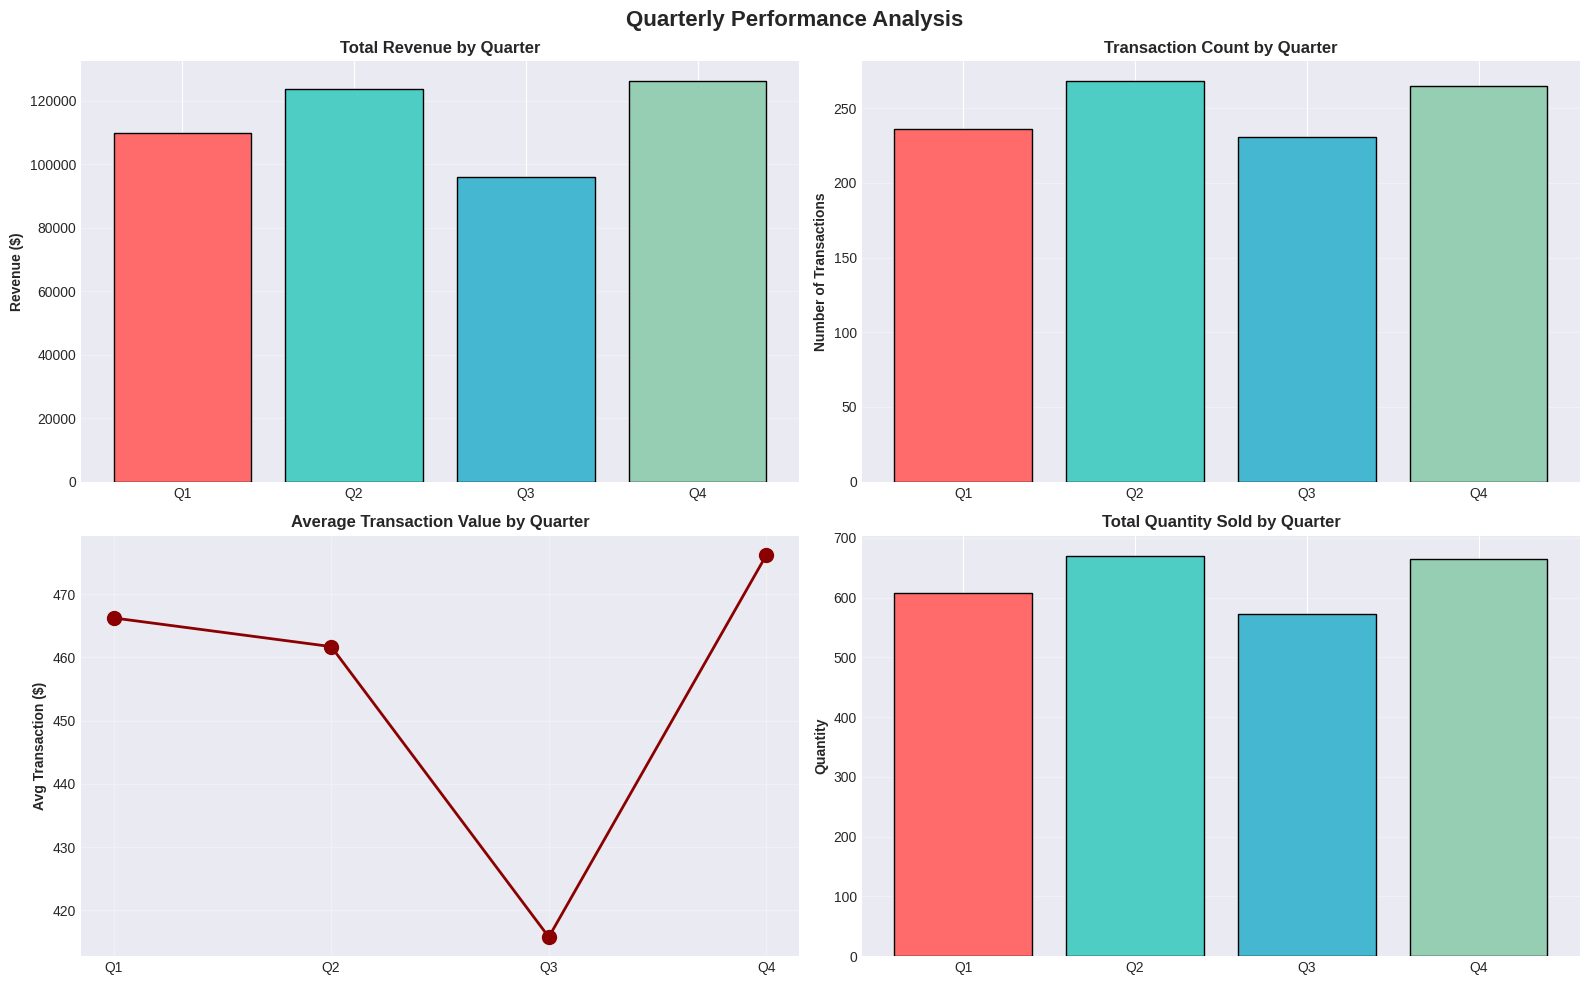


QUARTERLY PERFORMANCE SUMMARY:
Quarter  Total_Revenue  Avg_Transaction  Transaction_Count  Total_Quantity
     Q1         110030           466.23                236             607
     Q2         123735           461.70                268             670
     Q3          96045           415.78                231             573
     Q4         126190           476.19                265             664


In [73]:
# Quarterly analysis
quarterly_sales = df.groupby('Quarter').agg({
    'Total Amount': ['sum', 'mean'],
    'Transaction ID': 'count',
    'Quantity': 'sum'
}).reset_index()
quarterly_sales.columns = ['Quarter', 'Total_Revenue', 'Avg_Transaction', 'Transaction_Count', 'Total_Quantity']
quarterly_sales['Quarter'] = 'Q' + quarterly_sales['Quarter'].astype(str)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Quarterly Performance Analysis', fontsize=16, fontweight='bold')

# Revenue by quarter
axes[0, 0].bar(quarterly_sales['Quarter'], quarterly_sales['Total_Revenue'],
              color=['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4'], edgecolor='black')
axes[0, 0].set_title('Total Revenue by Quarter', fontweight='bold')
axes[0, 0].set_ylabel('Revenue ($)', fontweight='bold')
axes[0, 0].grid(True, alpha=0.3, axis='y')

# Transaction count by quarter
axes[0, 1].bar(quarterly_sales['Quarter'], quarterly_sales['Transaction_Count'],
              color=['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4'], edgecolor='black')
axes[0, 1].set_title('Transaction Count by Quarter', fontweight='bold')
axes[0, 1].set_ylabel('Number of Transactions', fontweight='bold')
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Average transaction value
axes[1, 0].plot(quarterly_sales['Quarter'], quarterly_sales['Avg_Transaction'],
               marker='o', linewidth=2, markersize=10, color='darkred')
axes[1, 0].set_title('Average Transaction Value by Quarter', fontweight='bold')
axes[1, 0].set_ylabel('Avg Transaction ($)', fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)

# Quantity by quarter
axes[1, 1].bar(quarterly_sales['Quarter'], quarterly_sales['Total_Quantity'],
              color=['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4'], edgecolor='black')
axes[1, 1].set_title('Total Quantity Sold by Quarter', fontweight='bold')
axes[1, 1].set_ylabel('Quantity', fontweight='bold')
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("\nQUARTERLY PERFORMANCE SUMMARY:")
print("="*80)
print(quarterly_sales.to_string(index=False))

## 6. Product Analysis <a id='section7'></a>

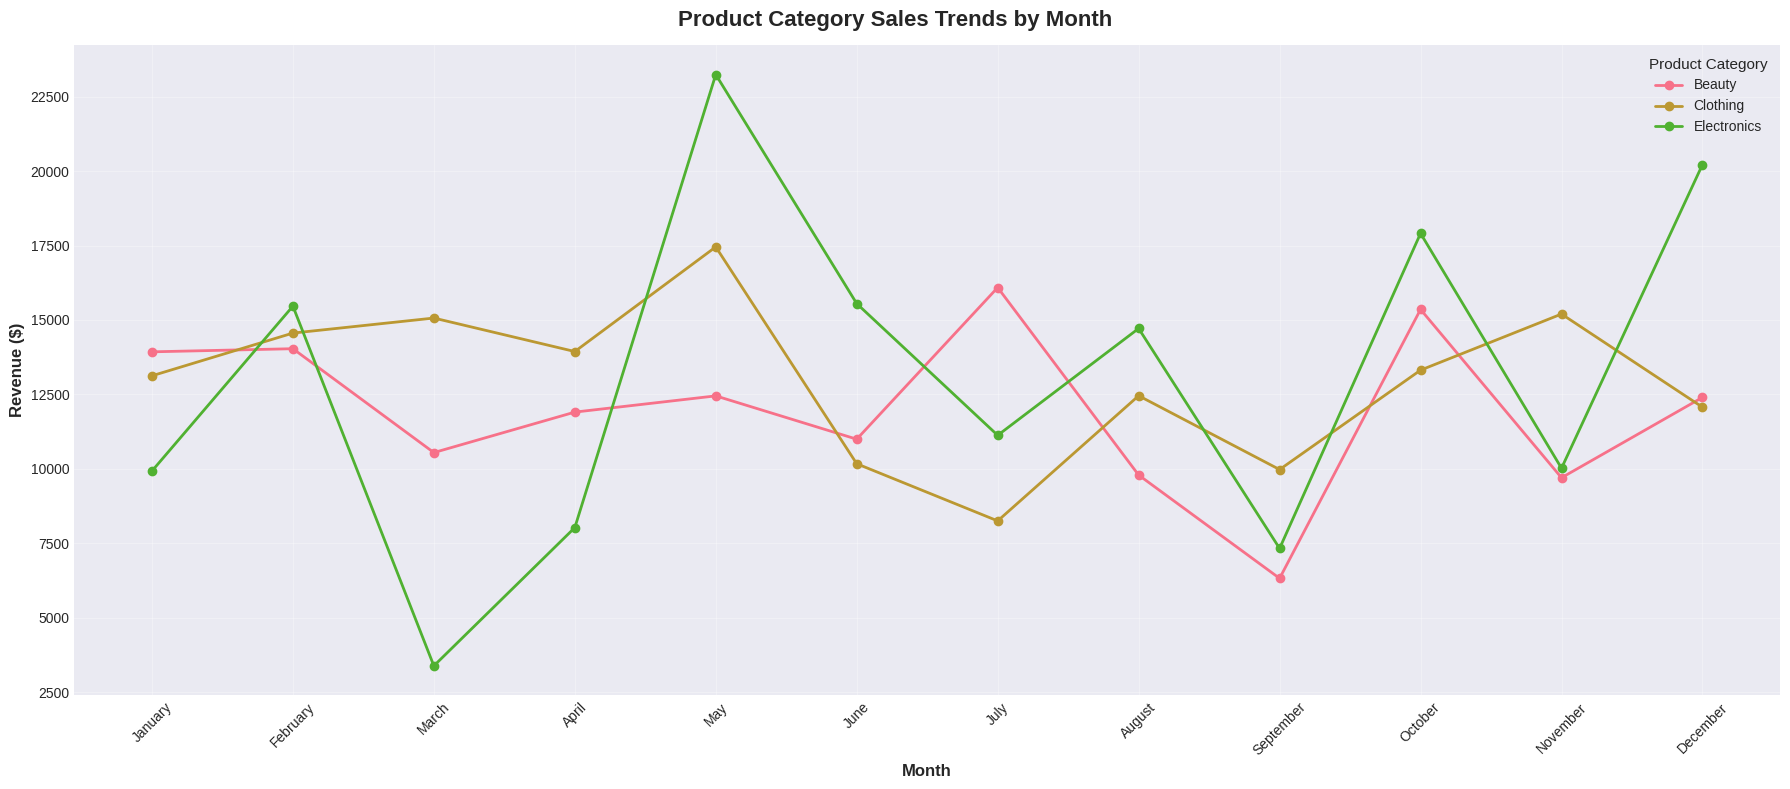

In [74]:
# Product category trends over time
product_monthly = df.groupby(['Month_Name', 'Product Category'])['Total Amount'].sum().reset_index()
product_monthly['Month_Name'] = pd.Categorical(product_monthly['Month_Name'],
                                               categories=month_order, ordered=True)
product_monthly = product_monthly.sort_values('Month_Name')

fig, ax = plt.subplots(figsize=(18, 8))
fig.suptitle('Product Category Sales Trends by Month', fontsize=16, fontweight='bold')

for category in df['Product Category'].unique():
    category_data = product_monthly[product_monthly['Product Category'] == category]
    ax.plot(category_data['Month_Name'], category_data['Total Amount'],
           marker='o', linewidth=2, markersize=6, label=category)

ax.set_xlabel('Month', fontweight='bold', fontsize=12)
ax.set_ylabel('Revenue ($)', fontweight='bold', fontsize=12)
ax.legend(title='Product Category', fontsize=10, title_fontsize=11)
ax.grid(True, alpha=0.3)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## 7. Multivariate Analysis <a id='section9'></a>




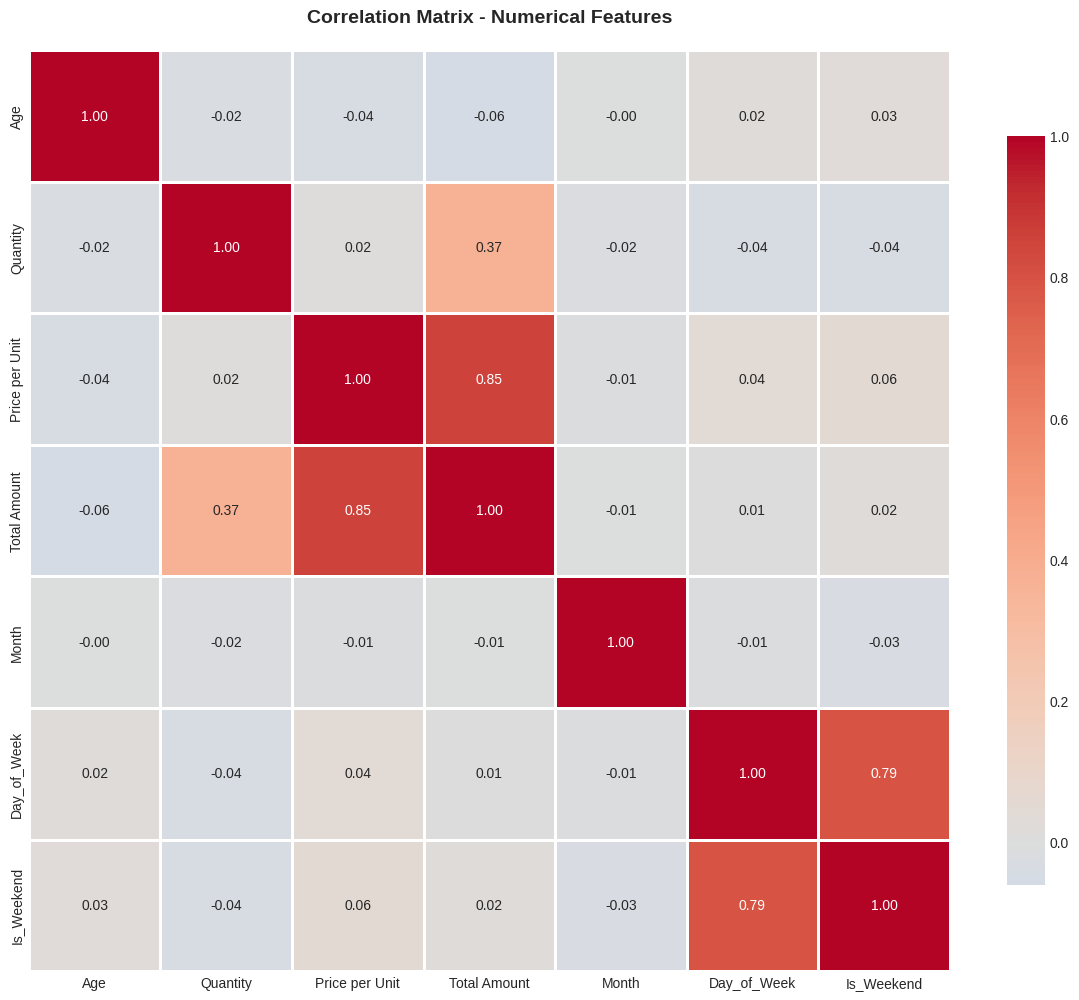


STRONG CORRELATIONS (|r| > 0.5):
Price per Unit       <-> Total Amount         : 0.852
Day_of_Week          <-> Is_Weekend           : 0.794


In [75]:
# Correlation analysis
numerical_features_corr = ['Age', 'Quantity', 'Price per Unit', 'Total Amount',
                          'Month', 'Day_of_Week', 'Is_Weekend']

correlation_matrix = df[numerical_features_corr].corr()

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
           square=True, linewidths=1, cbar_kws={"shrink": 0.8},
           fmt='.2f', ax=ax)
ax.set_title('Correlation Matrix - Numerical Features', fontweight='bold', fontsize=14, pad=20)
plt.tight_layout()
plt.show()

print("\nSTRONG CORRELATIONS (|r| > 0.5):")
print("="*80)
strong_corr = correlation_matrix[abs(correlation_matrix) > 0.5]
for i in range(len(strong_corr.columns)):
    for j in range(i+1, len(strong_corr.columns)):
        if abs(strong_corr.iloc[i, j]) > 0.5:
            print(f"{strong_corr.columns[i]:20s} <-> {strong_corr.columns[j]:20s} : {strong_corr.iloc[i, j]:.3f}")

## 8. Outlier Detection <a id='section10'></a>

In [76]:
# Outlier detection using IQR method
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return outliers, lower_bound, upper_bound

print("OUTLIER DETECTION ANALYSIS")
print("="*80)

outlier_columns = ['Total Amount', 'Quantity', 'Age']

outlier_summary = []
for col in outlier_columns:
    outliers, lower, upper = detect_outliers_iqr(df, col)
    outlier_summary.append({
        'Feature': col,
        'Total_Outliers': len(outliers),
        'Percentage': f"{len(outliers)/len(df)*100:.2f}%",
        'Lower_Bound': f"{lower:.2f}",
        'Upper_Bound': f"{upper:.2f}",
        'Min_Outlier': f"{outliers[col].min():.2f}" if len(outliers) > 0 else 'N/A',
        'Max_Outlier': f"{outliers[col].max():.2f}" if len(outliers) > 0 else 'N/A'
    })

outlier_df = pd.DataFrame(outlier_summary)
print(outlier_df.to_string(index=False))

OUTLIER DETECTION ANALYSIS
     Feature  Total_Outliers Percentage Lower_Bound Upper_Bound Min_Outlier Max_Outlier
Total Amount               0      0.00%    -1200.00     2160.00         N/A         N/A
    Quantity               0      0.00%       -3.50        8.50         N/A         N/A
         Age               0      0.00%       -7.00       89.00         N/A         N/A


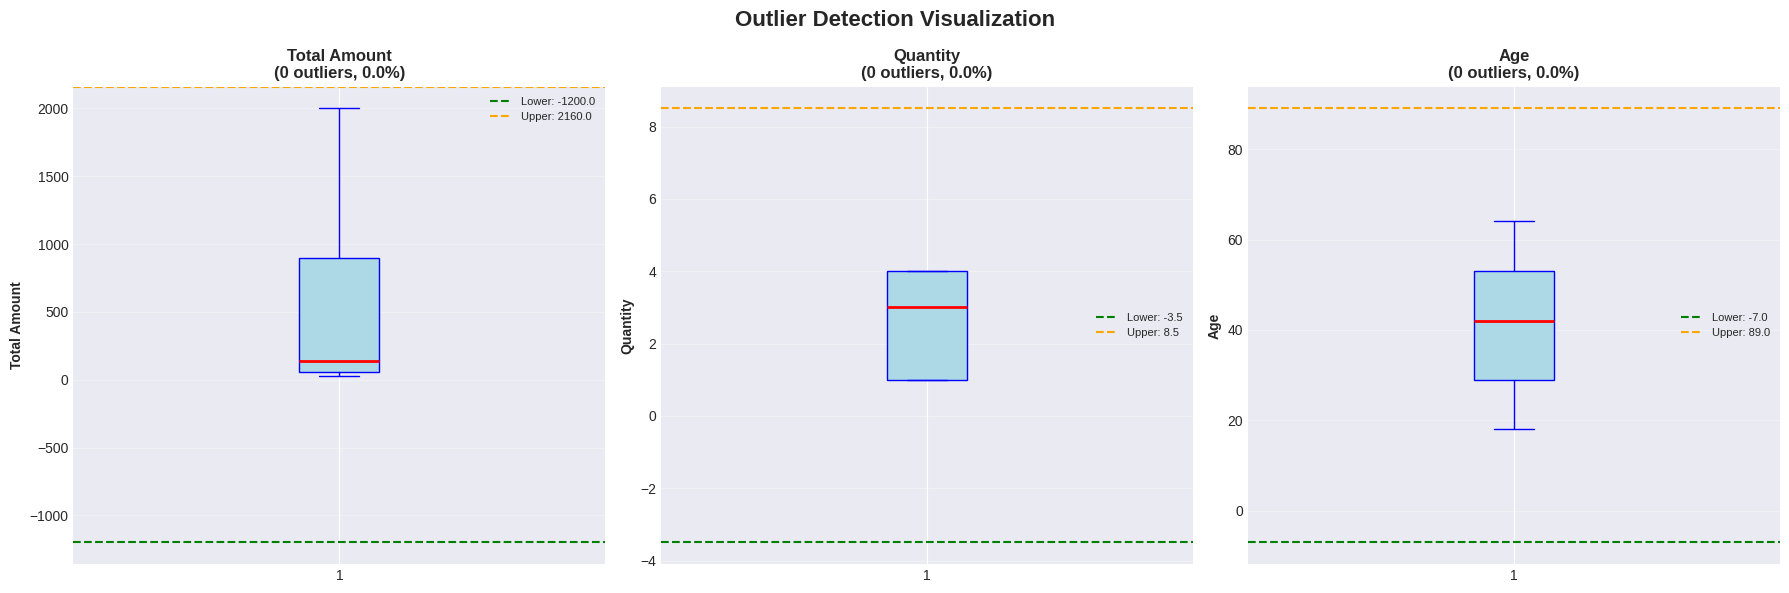

In [77]:
# Visualize outliers
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Outlier Detection Visualization', fontsize=16, fontweight='bold')

for idx, col in enumerate(outlier_columns):
    outliers, lower, upper = detect_outliers_iqr(df, col)

    # Box plot with outliers highlighted
    bp = axes[idx].boxplot(df[col], vert=True, patch_artist=True,
                          boxprops=dict(facecolor='lightblue', color='blue'),
                          whiskerprops=dict(color='blue'),
                          capprops=dict(color='blue'),
                          medianprops=dict(color='red', linewidth=2),
                          flierprops=dict(marker='o', markerfacecolor='red', markersize=8, alpha=0.7))

    axes[idx].set_title(f'{col}\n({len(outliers)} outliers, {len(outliers)/len(df)*100:.1f}%)',
                       fontweight='bold')
    axes[idx].set_ylabel(col, fontweight='bold')
    axes[idx].grid(True, alpha=0.3, axis='y')

    # Add horizontal lines for bounds
    axes[idx].axhline(lower, color='green', linestyle='--', linewidth=1.5, label=f'Lower: {lower:.1f}')
    axes[idx].axhline(upper, color='orange', linestyle='--', linewidth=1.5, label=f'Upper: {upper:.1f}')
    axes[idx].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 9. Business Insights & Recommendations <a id='section11'></a>

In [78]:
# Generate comprehensive business insights
print("="*80)
print("COMPREHENSIVE BUSINESS INSIGHTS & STRATEGIC RECOMMENDATIONS")
print("="*80)

# 1. Revenue and Sales Performance
total_revenue = df['Total Amount'].sum()
total_transactions = len(df)
avg_transaction = df['Total Amount'].mean()
unique_customers = df['Customer ID'].nunique()

print("\n" + "="*80)
print("1. OVERALL BUSINESS PERFORMANCE")
print("="*80)
print(f"   Total Revenue: ${total_revenue:,.2f}")
print(f"   Total Transactions: {total_transactions:,}")
print(f"   Average Transaction Value: ${avg_transaction:.2f}")
print(f"   Unique Customers: {unique_customers:,}")
print(f"   Average Revenue per Customer: ${total_revenue/unique_customers:.2f}")
print(f"   Customer Retention Rate: {(df.groupby('Customer ID').size() > 1).sum() / unique_customers * 100:.1f}%")

# 2. Best and Worst Performing Months
print("\n" + "="*80)
print("2. TEMPORAL PERFORMANCE INSIGHTS")
print("="*80)
best_month = monthly_sales.loc[monthly_sales['Total_Revenue'].idxmax()]
worst_month = monthly_sales.loc[monthly_sales['Total_Revenue'].idxmin()]
print(f"   Best Performing Month: {best_month['Month']} (${best_month['Total_Revenue']:,.2f})")
print(f"   Worst Performing Month: {worst_month['Month']} (${worst_month['Total_Revenue']:,.2f})")
print(f"   Revenue Variance: {((best_month['Total_Revenue'] - worst_month['Total_Revenue']) / worst_month['Total_Revenue'] * 100):.1f}%")

best_day = dow_sales.loc[dow_sales['Total_Revenue'].idxmax()]
worst_day = dow_sales.loc[dow_sales['Total_Revenue'].idxmin()]
print(f"\n   Best Performing Day: {best_day['Day']} (${best_day['Total_Revenue']:,.2f})")
print(f"   Lowest Performing Day: {worst_day['Day']} (${worst_day['Total_Revenue']:,.2f})")
print(f"   Weekend Revenue Share: {weekend_sales/total_revenue*100:.1f}%")
print(f"   Weekday Revenue Share: {weekday_sales/total_revenue*100:.1f}%")

# 3. Product Category Insights
print("\n" + "="*80)
print("3. PRODUCT CATEGORY PERFORMANCE")
print("="*80)
top_category = product_analysis.iloc[0]
print(f"   Top Category: {top_category['Product_Category']}")
print(f"      - Revenue: ${top_category['Total_Revenue']:,.2f} ({top_category['Revenue_Share_%']}% market share)")
print(f"      - Transactions: {top_category['Transaction_Count']} ({top_category['Transaction_Share_%']}% share)")
print(f"      - Average Transaction: ${top_category['Avg_Transaction']:.2f}")
print(f"      - Unique Customers: {top_category['Unique_Customers']}")

# 5. Gender-based Insights
print("\n" + "="*80)
print("5. DEMOGRAPHIC INSIGHTS")
print("="*80)
for _, row in gender_analysis.iterrows():
    print(f"   {row['Gender']} Customers:")
    print(f"      - Total Revenue: ${row['Total_Revenue']:,.2f} ({row['Total_Revenue']/total_revenue*100:.1f}% share)")
    print(f"      - Average Transaction: ${row['Avg_Transaction']:.2f}")
    print(f"      - Number of Customers: {row['Unique_Customers']}")

# 6. Age-based Insights
print("\n   Age Group Analysis:")
top_age_group = age_analysis.loc[age_analysis['Total_Revenue'].idxmax()]
print(f"      - Highest Spending Age Group: {top_age_group['Age_Group']}")
print(f"      - Revenue: ${top_age_group['Total_Revenue']:,.2f}")
print(f"      - Average Transaction: ${top_age_group['Avg_Transaction']:.2f}")

COMPREHENSIVE BUSINESS INSIGHTS & STRATEGIC RECOMMENDATIONS

1. OVERALL BUSINESS PERFORMANCE
   Total Revenue: $456,000.00
   Total Transactions: 1,000
   Average Transaction Value: $456.00
   Unique Customers: 1,000
   Average Revenue per Customer: $456.00
   Customer Retention Rate: 0.0%

2. TEMPORAL PERFORMANCE INSIGHTS
   Best Performing Month: May ($53,150.00)
   Worst Performing Month: September ($23,620.00)
   Revenue Variance: 125.0%

   Best Performing Day: Saturday ($78,815.00)
   Lowest Performing Day: Thursday ($53,835.00)
   Weekend Revenue Share: 30.1%
   Weekday Revenue Share: 69.9%

3. PRODUCT CATEGORY PERFORMANCE
   Top Category: Electronics
      - Revenue: $156,905.00 (34.41% market share)
      - Transactions: 342 (34.2% share)
      - Average Transaction: $458.79
      - Unique Customers: 342

5. DEMOGRAPHIC INSIGHTS
   Female Customers:
      - Total Revenue: $232,840.00 (51.1% share)
      - Average Transaction: $456.55
      - Number of Customers: 510
   Male Cu

In [79]:
# Additional Data Requirements
print("\n" + "="*80)
print("ADDITIONAL DATA REQUIREMENTS FOR ENHANCED DECISION-MAKING")
print("="*80)

print("\n1. CUSTOMER INSIGHTS:")
print("   • Geographic location (city, state, region) for regional analysis")
print("   • Customer acquisition channel (online, in-store, referral, social media)")
print("   • Customer lifetime value and historical purchase patterns")
print("   • Email engagement metrics (open rates, click-through rates)")
print("   • Customer satisfaction scores and feedback")
print("   • Preferred communication channels and shopping times")


print("\n2. TRANSACTION DETAILS:")
print("   • Payment method used (credit card, debit, cash, digital wallet)")
print("   • Discount codes applied and promotion effectiveness")
print("   • Shopping cart abandonment data")
print("   • Cross-sell and upsell opportunities identified")
print("   • Shipping method and delivery times (if applicable)")

print("\n3. MARKET CONTEXT:")
print("   • Competitor pricing and promotional activities")
print("   • Economic indicators (consumer confidence, unemployment rates)")
print("   • Weather data (for correlation with sales patterns)")
print("   • Social media sentiment and brand mentions")
print("   • Industry benchmarks and market trends")



ADDITIONAL DATA REQUIREMENTS FOR ENHANCED DECISION-MAKING

1. CUSTOMER INSIGHTS:
   • Geographic location (city, state, region) for regional analysis
   • Customer acquisition channel (online, in-store, referral, social media)
   • Customer lifetime value and historical purchase patterns
   • Email engagement metrics (open rates, click-through rates)
   • Customer satisfaction scores and feedback
   • Preferred communication channels and shopping times

2. TRANSACTION DETAILS:
   • Payment method used (credit card, debit, cash, digital wallet)
   • Discount codes applied and promotion effectiveness
   • Shopping cart abandonment data
   • Cross-sell and upsell opportunities identified
   • Shipping method and delivery times (if applicable)

3. MARKET CONTEXT:
   • Competitor pricing and promotional activities
   • Economic indicators (consumer confidence, unemployment rates)
   • Weather data (for correlation with sales patterns)
   • Social media sentiment and brand mentions
   • Ind